# 方板含非恒定体力：高阶复变核、纯边界训练

此版本采用已经推导的零阶 KM 点力位移核 K0 和第一阶高阶复位移核 K1，不使用解析特解，不采用内部 PDE 训练配点。原来的三角函数算例替换为满足 L(f)=0 的多项式解析算例。边界辅助条件是必要的，不是仅靠原位移/牵引条件训练。

## 算例

无量纲区域 $\Omega=[0,1]^2$。平面应变，$\lambda=1$、$\mu=0.5$、$\nu=1/3$，$\beta=0.2$。定义解析解

$$u_x=\nu x+\beta(x^3+xy^2),\qquad u_y=-y+\beta(y^3+x^2y).$$

令 $\ell=\lambda+2\mu$。三个应力为

$$\sigma_{xx}=\ell[\nu+\beta(3x^2+y^2)]+\lambda[-1+\beta(3y^2+x^2)],$$

$$\sigma_{yy}=\lambda[\nu+\beta(3x^2+y^2)]+\ell[-1+\beta(3y^2+x^2)],$$

$$\sigma_{xy}=4\mu\beta xy.$$

采用 $\operatorname{div}\boldsymbol\sigma+\boldsymbol f=0$，体力为

$$\boxed{\boldsymbol f=-8\beta(\lambda+2\mu)(x,y)^T=(-3.2x,-3.2y)^T.}$$

体力不是常数，而且 $\mathcal L\boldsymbol f=0$，因此可以采用文献第 2.4 节的二次 Navier 算子路线。

上下边指定解析解给出的两个位移；左右边指定上述解析应力对应的牵引：右边为 $(\sigma_{xx},\sigma_{xy})$，左边为 $(-\sigma_{xx},-\sigma_{xy})$。代码直接约束竖直边的 $\sigma_{xx},\sigma_{xy}$，与相应牵引条件等价。训练函数使用显式边界表达式，不调用内部解析解。

## 核函数与训练

令 $W=u_x+i u_y$、$F=f_x+i f_y$、$w=z-s$、$r=|w|$。使用

$$K_0=-\frac{1}{4\pi}\left(\frac1\mu+\frac1\ell\right)\ln r\,P+\frac{1}{8\pi}\left(\frac1\mu-\frac1\ell\right)\frac{w}{\bar w}\bar P,$$

$$K_1=-\frac{r^2}{16\pi}\left(\frac1{\mu^2}+\frac1{\ell^2}\right)(\ln r-1)P+\frac{w^2}{32\pi}\left(\frac1{\mu^2}-\frac1{\ell^2}\right)\left(\ln r-\frac34\right)\bar P.$$

源点位于域外，核满足 $\mathcal L_cK_0=0$、$\mathcal L_cK_1=K_0$。总位移是

$$W_\theta=\sum_jK_0(z-s_j;C_j)+\sum_jK_1(z-s_j;D_j).$$

训练包含原边界条件和辅助边界关系

$$\mathcal L_cW_\theta+F=\sum_jK_0(z-s_j;D_j)+F=0,\qquad z\in\Gamma.$$

总损失为归一化原边界损失、辅助边界损失及微小系数正则化之和。代码默认位移尺度 1、应力损失尺度 2、体力损失尺度 4；原边界损失按每条边取均方并求和，辅助损失按整个边界取均方。因此打印损失的数量级与未经归一化的物理残差不同。

由于 $\mathcal L_c^2W_\theta=0$ 和 $\mathcal L_cF=0$，原平衡残差 $R=\mathcal L_cW_\theta+F$ 满足 $\mathcal L_cR=0$。理想的连续边界条件 $R|_\Gamma=0$ 可通过 Navier Dirichlet 问题的唯一性推出 $R=0$。有限边界配点和优化只近似实现该关系，所以仍须独立验证域内平衡。

高阶部分是复位移核，不是直接套用原来两个全纯 KM 势的新增项。代码使用等价实数分量计算核，并通过物理坐标下的位移导数重构应力；避免 Windows 上复杂 CUDA 复数函数的兼容问题。

## 默认配置

- 四组初值：源尺度 $\alpha_0=1.15,1.30,1.40,1.50$。
- 每边 16 个虚拟源点，共 64 个几何源点；每点分别配置 K0 和 K1 的两个实系数，共 256 个核系数；加上一个源尺度，共 257 个可训练参数。
- 每条物理边界 100 个点，共 400 个训练点。原边界损失和辅助损失都使用这些边界点。
- 零系数冷启动；列归一化，不求初始最小二乘解，不采用变量投影。
- LM 联合更新核系数和源尺度，默认 120 次外迭代。源尺度通过 sigmoid 限制在 1.03 至 2.20，确保虚拟源点不进入物理域。
- 默认 CUDA、float64。没有 CUDA 的环境需把 `cfg['device']='cpu'`；不会静默回退。
- 不同初值使用相同点数、材料、载荷与停止设置。

`monitor_z` 是 31×31 的内部诊断网格，只计算误差和体力平衡检查，不传入训练残差或 Jacobian。101×101 网格只用于最终误差表与云图。系统矩阵构造包含检查，确保所有训练坐标都在物理边界。

最终运行只按独立边界的原条件损失与辅助损失之和选择，不按内部解析解误差选择。

## 运行与结果

依赖：numpy、torch、matplotlib。可运行 Python 脚本或 Notebook，二者求解代码一致。运行结束默认保存到 `square_body_force_boundary_only_results`：

- `adaptive_training.png`：四组初值的源尺度、总独立边界损失、位移相对 L2 和应力相对 L2 曲线。
- `full_field_comparison_5x2.png/pdf`：五行对应 ux、uy、sxx、syy、sxy，两列为解析解与核网络结果，每行统一色标，颜色条与云图等高、端部平齐。
- `adaptive_errors_and_time.csv`：各初值的五个物理量误差、边界损失、辅助边界损失、内部平衡诊断和训练时间。
- `history_alpha_*.csv`：各组完整迭代历史。
- `fields_and_coefficients.npz`：标准全场数据、系数、源点及最终源尺度。
- `settings_and_validation.json`：训练设置及独立检查，其中 `training_interior_points=0`。

物理尺度默认 L=1 m、E=1 MPa、U_ref=1e-4 m；对应应力尺度为 75 Pa，体力尺度为 75 N/m³。所有 PDE 与训练计算均在无量纲坐标下执行。

本版本用于满足 L(f)=0 的这个算例。若修改成不满足该条件的体力，必须同步调整高阶核与辅助关系；不能只替换 `body_force_fields` 后仍声称纯边界理论成立。

## 本次 CPU 验证

四组零系数冷启动均完成 120 次联合 LM 迭代。按独立边界损失选择的运行为初值 1.40，最终源尺度 1.425990。101×101 输出网格上的相对 L2 误差：

| ux | uy | sxx | syy | sxy |
|---:|---:|---:|---:|---:|
| 1.023e-5 | 4.935e-6 | 5.250e-5 | 5.160e-5 | 2.480e-4 |

原边界条件归一化损失之和为 3.287e-10，辅助边界损失为 5.363e-10；独立内部诊断网格上的体力平衡相对残差为 8.865e-6。空间自动微分与核递推得到的平衡残差差异为 1.80e-14，本构关系差异为 5.22e-15。

记录的运行时间包含初始化及每轮内部诊断，不包含最终云图输出；不宜直接与采用其他监测频率的 PINN 时间比较。代码默认 CUDA，但本次验证环境只有 CPU，未验证用户显卡上的运行和耗时。


In [1]:
"""Pure-boundary high-order complex Navier kernels: square plate with body force.

Pure boundary training for a polynomial body force satisfying L(f)=0.
Only physical-boundary conditions and auxiliary boundary force relations
enter the objective. Interior grids are used for diagnostics/export only.
CUDA is the default; set cfg['device']='cpu' for a CPU-only environment.
"""
import numpy as np
import torch
from torch import nn
import math
import matplotlib.pyplot as plt
from pathlib import Path
import csv
import time
import json

# Physical fields: x=L*x*, u=U_ref*u*, sigma=Sigma_ref*sigma*.
cfg = dict(L=1.0, E_real=1.0e6, nu=1/3, U_ref=1.0e-4,
           n_source_per_side=16, n_boundary_per_side=100,
           kernel_order=1, beta=0.2,
           stress_loss_scale=2., force_loss_scale=4.,
           alpha_initials=[1.15,1.30,1.40,1.50], alpha_min=1.03, alpha_max=2.20,
           warm_start=False, source_parameter_scale=1.0,
           regularization=1e-16, lm_steps=120, lm_initial_damping=1e-3,
           lm_min_damping=1e-14, lm_max_damping=1e12, lm_max_trials=10,
           lm_source_step_limit=0.03, lm_tol_loss=1e-14, lm_tol_step=1e-12,
           print_every=5, nx_plot=101, legend_fontsize=15, label_fontsize=14,
           device='cuda', cuda_fallback_to_cpu=False, save_outputs=True, output_dir='square_body_force_boundary_only_results')
dtype = torch.float64
if cfg['kernel_order'] != 1:
    raise ValueError('This boundary-only benchmark is formulated for K0+K1; keep kernel_order=1.')
# Windows NVRTC may not find its builtins DLL even when a GPU is visible.
# Keep directory handles alive for the lifetime of the notebook kernel.
import os
import sys
_dll_directory_handles = []
if os.name == 'nt' and hasattr(os, 'add_dll_directory'):
    cuda_version = torch.version.cuda or ''
    suffix = cuda_version.replace('.', '')
    builtin_name = f'nvrtc-builtins64_{suffix}.dll'
    candidates = [Path(torch.__file__).resolve().parent/'lib',
                  Path(sys.prefix)/'Library'/'bin']
    if os.environ.get('CUDA_PATH'):
        candidates.append(Path(os.environ['CUDA_PATH'])/'bin')
    for directory in candidates:
        if (directory/builtin_name).is_file():
            _dll_directory_handles.append(os.add_dll_directory(str(directory)))

def _cuda_complex_probe(selected_device):
    # Training uses real float64 tensors only; avoid complex CUDA Jiterator kernels.
    x=torch.linspace(.2,1.2,128,dtype=torch.float64,device=selected_device,requires_grad=True)
    y=.3*x+.1
    r2=x*x+y*y
    ir,ii=x/r2,-y/r2
    lr,li=.5*torch.log(r2),torch.atan2(y,x)
    value=(lr+li+ir+ii+ir*ir-ii*ii).square().sum()
    value.backward();torch.cuda.synchronize(selected_device)

def select_device(requested='auto', fallback=True, probe=None):
    selected = torch.device(('cuda' if torch.cuda.is_available() else 'cpu')
                            if requested == 'auto' else requested)
    if selected.type == 'cuda':
        try:
            (_cuda_complex_probe if probe is None else probe)(selected)
        except (RuntimeError, OSError, AssertionError) as error:
            if not fallback:
                raise
            # Do not print the thousands of lines of generated CUDA source.
            lines = str(error).strip().splitlines()
            reason = next((line.strip() for line in lines
                           if 'nvrtc:' in line or 'failed to open' in line),
                          lines[-1] if lines else type(error).__name__)
            print('CUDA float64-operation check failed:', reason)
            print('Switching this run to CPU. Set cfg["device"]="cpu" to skip the CUDA check.')
            selected = torch.device('cpu')
    return selected

if cfg['warm_start']:
    raise ValueError('This notebook uses zero-coefficient cold starts. Keep warm_start=False.')
device = select_device(cfg['device'], cfg['cuda_fallback_to_cpu'])
if device.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
np.random.seed(42)
torch.manual_seed(42)
L, E_real, nu, U_ref = (cfg[k] for k in ('L', 'E_real', 'nu', 'U_ref'))
# Chosen nondimensional material: lambda=1, mu=0.5.
# These imply E*=4/3 and nu=1/3 in plane strain.
if not np.isclose(nu, 1/3):
    raise ValueError('This plane-strain benchmark uses nu=1/3.')
mu, lam, kappa = 0.5, 1.0, 3-4*nu
E_star = 4/3
Sigma_ref = E_real*U_ref/(E_star*L)
F_ref = Sigma_ref/L
print('PURE BOUNDARY TRAINING; K0 + K1; NO analytical particular solution')
print('Device:', device, '| float64 | plane strain | lambda*=1, mu*=0.5, beta=', cfg['beta'])
print('Physical scales: displacement=', U_ref, 'm; stress=', Sigma_ref, 'Pa')




PURE BOUNDARY TRAINING; K0 + K1; NO analytical particular solution
Device: cuda | float64 | plane strain | lambda*=1, mu*=0.5, beta= 0.2
Physical scales: displacement= 0.0001 m; stress= 75.0 Pa


In [2]:
def tensor(x):
    is_complex = x.is_complex() if isinstance(x, torch.Tensor) else np.iscomplexobj(x)
    return torch.as_tensor(x, dtype=torch.complex128 if is_complex else dtype, device=device)

def exact_fields(z):
    # Used ONLY for diagnostics and exported reference fields.
    x, y = z.real, z.imag
    beta = cfg['beta']
    ux = nu*x+beta*(x**3+x*y*y)
    uy = -y+beta*(y**3+x*x*y)
    ex = nu+beta*(3*x*x+y*y)
    ey = -1+beta*(3*y*y+x*x)
    shear = 4*beta*x*y
    return torch.stack((ux,uy,(lam+2*mu)*ex+lam*ey,
                        lam*ex+(lam+2*mu)*ey,mu*shear),-1)


def body_force_fields(z):
    # div(sigma)+f=0: nonconstant body force, and L(f)=0 exactly.
    return -8*cfg['beta']*(lam+2*mu)*torch.stack((z.real,z.imag),-1)


def boundary_columns(key):
    # Top/bottom: both displacements. Left/right: both traction components.
    # On a vertical side, prescribing sigma_xx,sigma_xy is equivalent to
    # prescribing traction with the corresponding outward-normal sign.
    return {'bottom':(0,1),'top':(0,1),'left':(2,4),'right':(2,4)}[key]


def prescribed_boundary(key,z):
    # Explicit prescribed boundary data; no interior exact fields in training.
    x, y = z.real, z.imag
    beta = cfg['beta']
    if key in ('bottom','top'):
        return torch.stack((nu*x+beta*(x**3+x*y*y),
                            -y+beta*(y**3+x*x*y)),-1)
    sx = (lam+2*mu)*(nu+beta*(3*x*x+y*y))+lam*(-1+beta*(3*y*y+x*x))
    sxy = 4*mu*beta*x*y
    return torch.stack((sx,sxy),-1)


def von_mises(q):
    sx, sy, t = q[..., 2], q[..., 3], q[..., 4]
    sz = nu*(sx+sy)
    return torch.sqrt(torch.clamp(((sx-sy)**2+(sy-sz)**2+(sz-sx)**2)/2+3*t*t, min=0))

def boundary_points(n, held_out=False):
    # Training and independent validation points do not coincide.
    t = (np.arange(n)+(0.5 if held_out else 0.25))/n
    return {key: tensor(z) for key, z in dict(bottom=t+0j, top=t+1j,
            left=1j*t, right=1+1j*t).items()}


def polyharmonic_derivative(t, n, k):
    """d^k/dt^k F_n(sqrt(t)); t>0 because every source is external."""
    harmonic = sum(1/j for j in range(1, n+1))
    const = 1/(2*np.pi*4**n*math.factorial(n)**2)
    if k <= n:
        falling = math.factorial(n)/math.factorial(n-k)
        correction = .5*sum(1/j for j in range(n-k+1, n+1))
        return const*falling*t**(n-k)*(.5*torch.log(t)-harmonic+correction)
    return (const*.5*math.factorial(n)*(-1)**(k-n-1)
            *math.factorial(k-n-1)*t**(n-k))


def higher_kernel_fields(z, sr, si, m):
    """Real/imag evaluation of the derived complex kernel K_m P.

    Output [point, force coefficient (source x/y interleaved), five fields].
    Stresses follow physical-coordinate Hooke's law, not homogeneous KM
    reconstruction applied incorrectly to a nonhomogeneous displacement.
    """
    x, y = z.real[:, None]-sr[None, :], z.imag[:, None]-si[None, :]
    t = x*x+y*y
    a = -mu**(-m-1)
    b = mu**(-m-1)-(lam+2*mu)**(-m-1)
    D = a*polyharmonic_derivative(t, m, 0)+2*b*polyharmonic_derivative(t, m+1, 1)
    C = 4*b*polyharmonic_derivative(t, m+1, 2)
    Dt = a*polyharmonic_derivative(t, m, 1)+2*b*polyharmonic_derivative(t, m+1, 2)
    Ct = 4*b*polyharmonic_derivative(t, m+1, 3)
    ux = torch.stack((D+C*x*x, C*x*y), -1)
    uy = torch.stack((C*x*y, D+C*y*y), -1)
    ex = torch.stack((2*x*Dt+2*x**3*Ct+2*x*C, 2*x*x*y*Ct+y*C), -1)
    ey = torch.stack((2*x*y*y*Ct+x*C, 2*y*Dt+2*y**3*Ct+2*y*C), -1)
    uxy = torch.stack((2*y*Dt+2*x*x*y*Ct, 2*x*y*y*Ct+x*C), -1)
    uyx = torch.stack((2*x*x*y*Ct+y*C, 2*x*Dt+2*x*y*y*Ct), -1)
    return torch.stack((ux, uy, (lam+2*mu)*ex+lam*ey,
                        lam*ex+(lam+2*mu)*ey, mu*(uxy+uyx)), -1).reshape(len(z), -1, 5)


class HigherOrderComplexNet(nn.Module):
    def __init__(self, alpha0):
        super().__init__()
        if not cfg['alpha_min'] < alpha0 < cfg['alpha_max']:
            raise ValueError('Initial source scale must lie strictly inside alpha_min, alpha_max.')
        n = cfg['n_source_per_side']
        t = np.linspace(-.5, .5, n+2)[1:-1]
        base = np.concatenate((t-.5j, .5+1j*t, t[::-1]+.5j, -.5+1j*t[::-1]))
        self.register_buffer('base', tensor(base))
        self.ns = len(base)
        self.nc = 2*self.ns*(cfg['kernel_order']+1)
        fraction = (alpha0-cfg['alpha_min'])/(cfg['alpha_max']-cfg['alpha_min'])
        self.eta = nn.Parameter(tensor(np.log(fraction/(1-fraction))))
        self.register_buffer('coefficient_map', torch.eye(self.nc, dtype=dtype, device=device))
        self.theta = nn.Parameter(torch.zeros(self.nc, dtype=dtype, device=device))

    def alpha(self, eta=None):
        return cfg['alpha_min']+(cfg['alpha_max']-cfg['alpha_min'])*torch.sigmoid(self.eta if eta is None else eta)

    def source_coordinates(self, eta=None):
        return .5+self.alpha(eta)*self.base.real, .5+self.alpha(eta)*self.base.imag

    def sources(self):
        sr, si = self.source_coordinates()
        return torch.complex(sr, si)

    def basis(self, z, eta=None):
        sr, si = self.source_coordinates(eta)
        return torch.cat([higher_kernel_fields(z, sr, si, m)
                          for m in range(cfg['kernel_order']+1)], 1)

    def navier_basis(self, z, eta=None):
        # Exact recursion L K_m=K_(m-1), m>=1; L K_0=0 outside sources.
        sr, si = self.source_coordinates(eta)
        zero = torch.zeros((len(z), 2*self.ns, 2), dtype=dtype, device=device)
        return torch.cat([zero]+[higher_kernel_fields(z, sr, si, m-1)[..., :2]
                                 for m in range(1, cfg['kernel_order']+1)], 1)

    def raw_coefficients(self):
        return self.coefficient_map@self.theta

    def total_fields(self, z):
        return torch.einsum('ncf,c->nf', self.basis(z), self.raw_coefficients())

    def force_residual(self, z):
        return (torch.einsum('ncf,c->nf', self.navier_basis(z), self.raw_coefficients())
                +body_force_fields(z))


def interior_points(n):
    t = (np.arange(n)+.5)/n
    X, Y = np.meshgrid(t, t)
    return tensor((X+1j*Y).ravel())


train_points = boundary_points(cfg['n_boundary_per_side'])
check_points = boundary_points(2*cfg['n_boundary_per_side']+1, True)
# Interior points below are diagnostic ONLY. Never passed to system_matrix.
monitor_z = interior_points(31)
monitor_ref = exact_fields(monitor_z).detach()


def system_matrix(model, points, eta=None):
    matrices, targets = [], []
    for key, z in points.items():
        assert bool(((z.real==0)|(z.real==1)|(z.imag==0)|(z.imag==1)).all())
        cols = list(boundary_columns(key))
        weights = tensor([1. if col<2 else cfg['stress_loss_scale'] for col in cols])
        basis = model.basis(z, eta)[..., cols]
        matrices.append((basis/weights[None, None, :]).permute(0, 2, 1)
                        .reshape(2*len(z), -1)/np.sqrt(len(z)))
        targets.append((prescribed_boundary(key, z)/weights).reshape(-1)/np.sqrt(len(z)))
    # Auxiliary relation L(u)+f=0 is imposed on the PHYSICAL BOUNDARY ONLY.
    boundary_z = torch.cat(list(points.values()))
    matrices.append(model.navier_basis(boundary_z, eta).permute(0, 2, 1)
                    .reshape(2*len(boundary_z), -1)/(cfg['force_loss_scale']*np.sqrt(len(boundary_z))))
    targets.append(-body_force_fields(boundary_z).reshape(-1)/(cfg['force_loss_scale']*np.sqrt(len(boundary_z))))
    return torch.cat(matrices), torch.cat(targets)


def initialize(model):
    # Column normalization only. No least-squares solution or reference warm start.
    with torch.no_grad():
        A, _ = system_matrix(model, train_points)
        scale = torch.linalg.vector_norm(A, dim=0).clamp_min(1e-30)
        model.coefficient_map = torch.diag(1/scale)
        assert torch.count_nonzero(model.raw_coefficients()).item() == 0
    print(f'  Cold start: all {model.nc} coefficients zero; joint source-scale optimization')


def data_residual(model, points, eta=None):
    A, b = system_matrix(model, points, eta)
    return A@model.raw_coefficients()-b


def lm_residual(model, eta=None):
    return torch.cat((data_residual(model, train_points, eta),
                      np.sqrt(cfg['regularization'])*model.theta))


def objective(model):
    return lm_residual(model).square().sum()


def independent_metrics(model):
    with torch.no_grad():
        edges = {}
        for key, z in check_points.items():
            cols = list(boundary_columns(key))
            weights = tensor([1. if c<2 else cfg['stress_loss_scale'] for c in cols])
            r = (model.total_fields(z)[:, cols]-prescribed_boundary(key, z))/weights
            edges[key] = r.square().sum(1).mean().item()
        f = model.force_residual(monitor_z)
        force_L2 = (torch.linalg.vector_norm(f)/torch.linalg.vector_norm(body_force_fields(monitor_z))).item()
        q = model.total_fields(monitor_z)
        du = torch.linalg.vector_norm(q[:, :2]-monitor_ref[:, :2])/torch.linalg.vector_norm(monitor_ref[:, :2])
        ds = torch.linalg.vector_norm(q[:, 2:]-monitor_ref[:, 2:])/torch.linalg.vector_norm(monitor_ref[:, 2:])
    boundary_z = torch.cat(list(check_points.values()))
    with torch.no_grad():
        aux = (model.force_residual(boundary_z)/cfg['force_loss_scale']).square().sum(1).mean().item()
    # Selection uses independent BOUNDARY data only, never interior diagnostics.
    return dict(boundary_loss=sum(edges.values()), auxiliary_boundary_loss=aux, force_L2=force_L2,
                displacement_L2=du.item(), stress_L2=ds.item(), edge_losses=edges,
                validation_loss=sum(edges.values())+aux)


def train_one(alpha0):
    if device.type == 'cuda': torch.cuda.synchronize()
    start = time.perf_counter()
    model = HigherOrderComplexNet(alpha0).to(device)
    initialize(model)
    damping = cfg['lm_initial_damping']
    history = []
    def record(epoch, accepted):
        row = dict(iteration=epoch, alpha=model.alpha().item(), objective=objective(model).item(),
                   damping=damping, accepted=accepted, **independent_metrics(model))
        row.pop('edge_losses')
        history.append(row)
        if epoch == 0 or epoch == 1 or epoch % cfg['print_every'] == 0:
            print(f"  {epoch:3d}: alpha={row['alpha']:.6f}, boundary={row['boundary_loss']:.2e}, "
                  f"aux BC={row['auxiliary_boundary_loss']:.2e}, interior force check={row['force_L2']:.2e}, u L2={row['displacement_L2']:.2e}, "
                  f"stress L2={row['stress_L2']:.2e}", flush=True)
        return row
    record(0, False)
    for epoch in range(1, cfg['lm_steps']+1):
        with torch.no_grad():
            r = lm_residual(model)
            A, _ = system_matrix(model, train_points)
            Jc = A@model.coefficient_map
            _, je = torch.func.jvp(lambda eta: data_residual(model, train_points, eta),
                                   (model.eta.detach(),), (torch.ones_like(model.eta),))
            J = torch.cat((Jc, je[:, None]), 1)
            nc = model.theta.numel()
            reg = torch.zeros((nc, nc+1), dtype=dtype, device=device)
            reg[:, :nc] = np.sqrt(cfg['regularization'])*torch.eye(nc, dtype=dtype, device=device)
            J = torch.cat((J, reg))
            scales = torch.linalg.vector_norm(J, dim=0).clamp_min(1e-12)
            K = J/scales
            G, g = K.T@K, K.T@r
            old_theta, old_eta = model.theta.clone(), model.eta.clone()
            old_alpha, value = model.alpha().item(), r.square().sum()
            accepted, step_norm = False, float('inf')
            for _ in range(cfg['lm_max_trials']):
                chol, info = torch.linalg.cholesky_ex(G+damping*torch.eye(nc+1, dtype=dtype, device=device))
                if info.item():
                    damping = min(damping*10, cfg['lm_max_damping']); continue
                step = torch.cholesky_solve((-g)[:, None], chol).squeeze(1)/scales
                new_alpha = model.alpha(old_eta+step[-1]).item()
                if abs(new_alpha-old_alpha)>cfg['lm_source_step_limit']:
                    target = old_alpha+np.sign(new_alpha-old_alpha)*cfg['lm_source_step_limit']
                    frac = (target-cfg['alpha_min'])/(cfg['alpha_max']-cfg['alpha_min'])
                    target_eta = np.log(frac/(1-frac))
                    step *= min(1., abs((target_eta-old_eta.item())/step[-1].item()))
                model.theta.copy_(old_theta+step[:nc]); model.eta.copy_(old_eta+step[-1])
                new_value = objective(model)
                predicted = value-(r+J@step).square().sum()
                rho = ((value-new_value)/predicted).item() if predicted.item()>0 else -1.
                if torch.isfinite(new_value) and new_value<value and rho>1e-4:
                    accepted = True; step_norm = torch.linalg.vector_norm(scales*step).item()
                    damping = max(cfg['lm_min_damping'], damping*(.3 if rho>.75 else 1.)); break
                model.theta.copy_(old_theta); model.eta.copy_(old_eta)
                damping = min(damping*10, cfg['lm_max_damping'])
        row = record(epoch, accepted)
        if row['objective']<cfg['lm_tol_loss'] or (accepted and step_norm<cfg['lm_tol_step']): break
        if not accepted and damping>=cfg['lm_max_damping']: break
    if device.type == 'cuda': torch.cuda.synchronize()
    return dict(model=model, history=history, alpha0=alpha0,
                elapsed=time.perf_counter()-start, metrics=independent_metrics(model))


def verify_kernel_recursion():
    # Independent spatial AD checks the analytic stress and recursion formulas.
    xy = tensor([[.21, .34], [.72, .63]]).requires_grad_(True)
    z = torch.complex(xy[:, 0], xy[:, 1]); sr, si = tensor([1.2]), tensor([-.3])
    errors = []
    for m in (0, 1, 2, cfg['kernel_order']):
        for component in (0, 1):
            q = higher_kernel_fields(z, sr, si, m)[:, component, :]
            gradients = [torch.autograd.grad(q[:, j].sum(), xy, retain_graph=True)[0] for j in (2, 3, 4)]
            navier = torch.stack((gradients[0][:, 0]+gradients[2][:, 1],
                                 gradients[2][:, 0]+gradients[1][:, 1]), 1)
            target = torch.zeros_like(navier) if m == 0 else higher_kernel_fields(z, sr, si, m-1)[:, component, :2]
            relative = ((navier-target).abs().max()/(1+target.abs().max())).item()
            errors.append(relative)
            assert relative < 2e-11, (m, component, relative)
            ug, vg = [torch.autograd.grad(q[:, j].sum(), xy, retain_graph=True)[0] for j in (0, 1)]
            hooke = torch.stack(((lam+2*mu)*ug[:, 0]+lam*vg[:, 1],
                                 lam*ug[:, 0]+(lam+2*mu)*vg[:, 1],
                                 mu*(ug[:, 1]+vg[:, 0])), 1)
            assert ((q[:, 2:]-hooke).abs().max()/(1+hooke.abs().max())).item()<2e-11
    # Zero order agrees with the original KM point-force displacement.
    wr, wi = z.real-sr[0], z.imag-si[0]
    P = .7-.4j
    c = tensor([P.real, P.imag])
    q0 = torch.einsum('ncf,c->nf', higher_kernel_fields(z, sr, si, 0), c)
    log_r = .5*torch.log(wr**2+wi**2)
    ratio_r, ratio_i = (wr*wr-wi*wi)/(wr*wr+wi*wi), 2*wr*wi/(wr*wr+wi*wi)
    cf = 1/(2*np.pi*(kappa+1))
    expected = torch.stack((-cf*kappa/mu*P.real*log_r+cf/(2*mu)*(ratio_r*P.real+ratio_i*P.imag),
                             -cf*kappa/mu*P.imag*log_r+cf/(2*mu)*(ratio_i*P.real-ratio_r*P.imag)), 1)
    assert (q0[:, :2]-expected).abs().max().item()<1e-12
    print('Kernel recursion AD check, maximum scaled discrepancy:', max(errors))
    return max(errors)


def verify_benchmark():
    xy = tensor([[.23,.37],[.62,.81]]).requires_grad_(True)
    z = torch.complex(xy[:,0],xy[:,1])
    q = exact_fields(z)
    gr = [torch.autograd.grad(q[:,j].sum(),xy,retain_graph=True)[0] for j in (2,3,4)]
    div = torch.stack((gr[0][:,0]+gr[2][:,1],gr[2][:,0]+gr[1][:,1]),1)
    error = (div+body_force_fields(z)).abs().max().item()
    assert error<1e-12, error
    # Linear body force has zero Hessian, hence L(f)=0 identically.
    H = torch.func.vmap(torch.func.hessian(
        lambda p: -8*cfg['beta']*(lam+2*mu)*p))(xy.detach())
    assert H.abs().max().item()==0
    for key, edge in check_points.items():
        error_bc=(exact_fields(edge)[:,list(boundary_columns(key))]-prescribed_boundary(key,edge)).abs().max().item()
        assert error_bc<1e-12
    print('Exact-solution equilibrium and prescribed boundary data verified; L(f)=0.')


def verify_trained_field(model):
    xy = tensor([[.173,.286],[.591,.724],[.837,.431]]).requires_grad_(True)
    z = torch.complex(xy[:,0],xy[:,1])
    q = model.total_fields(z)
    gradients=[torch.autograd.grad(q[:,j].sum(),xy,retain_graph=True)[0] for j in (2,3,4)]
    div=torch.stack((gradients[0][:,0]+gradients[2][:,1],gradients[2][:,0]+gradients[1][:,1]),1)
    recursive=model.force_residual(z)
    discrepancy=(div+body_force_fields(z)-recursive).abs().max().item()
    ug,vg=[torch.autograd.grad(q[:,j].sum(),xy,retain_graph=True)[0] for j in (0,1)]
    hooke=torch.stack(((lam+2*mu)*ug[:,0]+lam*vg[:,1],lam*ug[:,0]+(lam+2*mu)*vg[:,1],mu*(ug[:,1]+vg[:,0])),1)
    constitutive=(q[:,2:]-hooke).abs().max().item()
    assert discrepancy<1e-7 and constitutive<1e-7, (discrepancy,constitutive)
    print('Independent spatial-AD checks: recursion discrepancy=',discrepancy,
          '; constitutive discrepancy=',constitutive,
          '; physical equilibrium residual at test points=',(div+body_force_fields(z)).abs().max().item())
    return dict(recursion_discrepancy=discrepancy,constitutive_discrepancy=constitutive)




In [3]:
def export_results(runs):
    best = min(runs, key=lambda run: run['metrics']['validation_loss'])
    model = best['model']
    print('Selected using independent boundary loss only:', best['alpha0'], '->', model.alpha().item())
    physical_checks=verify_trained_field(model)
    axis = np.linspace(0, 1, cfg['nx_plot']); X, Y = np.meshgrid(axis, axis)
    z = tensor((X+1j*Y).ravel())
    with torch.no_grad():
        prediction = torch.cat([model.total_fields(chunk) for chunk in z.split(512)]).cpu().numpy()
        reference = exact_fields(z).cpu().numpy()
    scales = np.array([U_ref, U_ref, Sigma_ref, Sigma_ref, Sigma_ref])
    rows = []
    for run in runs:
        with torch.no_grad():
            pred = torch.cat([run['model'].total_fields(chunk) for chunk in z.split(512)]).cpu().numpy()
        errors = np.linalg.norm(pred-reference, axis=0)/np.linalg.norm(reference, axis=0)
        row = dict(alpha_initial=run['alpha0'], alpha_final=run['model'].alpha().item(),
                   time_seconds=run['elapsed'], boundary_loss=run['metrics']['boundary_loss'],
                   auxiliary_boundary_loss=run['metrics']['auxiliary_boundary_loss'], force_L2=run['metrics']['force_L2'])
        row.update(dict(zip(('ux_L2','uy_L2','sxx_L2','syy_L2','sxy_L2'), errors)))
        rows.append(row); print(row)
    out = Path(cfg['output_dir'])
    if cfg['save_outputs']:
        out.mkdir(parents=True, exist_ok=True)
        np.savez(out/'fields_and_coefficients.npz', X=X*L, Y=Y*L, prediction=prediction*scales,
                 reference=reference*scales, quantities=np.array(['ux','uy','sxx','syy','sxy']),
                 coefficients=model.raw_coefficients().detach().cpu().numpy(),
                 sources=model.sources().detach().cpu().numpy(), kernel_order=cfg['kernel_order'],
                 alpha=model.alpha().item())
        with (out/'settings_and_validation.json').open('w',encoding='utf-8') as stream:
            json.dump(dict(configuration=cfg,selected_alpha_initial=best['alpha0'],
                           training_boundary_points=sum(len(z) for z in train_points.values()),
                           training_interior_points=0,validation=physical_checks),stream,indent=2)
        with (out/'adaptive_errors_and_time.csv').open('w', newline='', encoding='utf-8-sig') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
        for run in runs:
            with (out/f"history_alpha_{run['alpha0']:.2f}.csv").open('w', newline='', encoding='utf-8-sig') as stream:
                writer=csv.DictWriter(stream, fieldnames=list(run['history'][0])); writer.writeheader(); writer.writerows(run['history'])
    plt.rcParams.update({'font.family':'serif', 'mathtext.fontset':'stix', 'font.size':12})
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
    for ax, key, label in zip(axes.ravel(), ('alpha','validation_loss','displacement_L2','stress_L2'),
                              (r'$\alpha$', 'Total boundary loss', r'Relative $L_2$ error of displacement', r'Relative $L_2$ error of stress')):
        for run in runs:
            history=run['history']; ax.plot([r['iteration'] for r in history], [r[key] for r in history],
                                           lw=1.8, label=rf"$\alpha_0={run['alpha0']:.2f}$")
        if key != 'alpha': ax.set_yscale('log')
        ax.set_xlabel('Iteration', fontsize=cfg['label_fontsize']); ax.set_ylabel(label, fontsize=cfg['label_fontsize'])
        if key == 'alpha':
            ax.set_ylim(cfg['alpha_min'],cfg['alpha_max'])
            ax.legend(loc='upper left',ncol=2,fontsize=cfg['legend_fontsize'],frameon=False)
        else:
            ax.legend(loc='upper right',fontsize=cfg['legend_fontsize'],frameon=False)
        ax.tick_params(direction='in')
    if cfg['save_outputs']: fig.savefig(out/'adaptive_training.png', dpi=300, bbox_inches='tight')
    fig, axes = plt.subplots(5, 2, figsize=(7.7, 15), dpi=140)
    fig.subplots_adjust(left=.14, right=.83, bottom=.04, top=.97, wspace=.2, hspace=.2)
    labels=(r'$u_x$',r'$u_y$',r'$\sigma_{xx}$',r'$\sigma_{yy}$',r'$\sigma_{xy}$')
    maps=[]
    for r in range(5):
        vmin=min(reference[:,r].min(),prediction[:,r].min())*scales[r]
        vmax=max(reference[:,r].max(),prediction[:,r].max())*scales[r]
        if r!=1: vmax=max(abs(vmin),abs(vmax)); vmin=-vmax
        for c, values in enumerate((reference[:,r]*scales[r], prediction[:,r]*scales[r])):
            ax=axes[r,c]
            im=ax.contourf(X,Y,values.reshape(X.shape), levels=np.linspace(vmin,vmax,101), cmap='coolwarm')
            ax.set_aspect('equal',adjustable='box'); ax.set_xticks([0,.5,1]); ax.set_yticks([0,.5,1])
            ax.tick_params(direction='in',labelbottom=(r==4),labelleft=(c==0))
            if c==0: ax.set_ylabel(r'$y$ (m)')
            if r==4: ax.set_xlabel(r'$x$ (m)')
            if r==0: ax.set_title(('Analytical','KM high-order')[c],fontsize=16)
        maps.append(im)
    fig.canvas.draw()
    for r, im in enumerate(maps):
        box=axes[r,1].get_position(); cax=fig.add_axes([box.x1+.025,box.y0,.022,box.height])
        cb=fig.colorbar(im,cax=cax); cb.set_label('Displacement (m)' if r<2 else 'Stress (Pa)')
        box=axes[r,0].get_position(); fig.text(.035,(box.y0+box.y1)/2,labels[r],rotation=90,va='center',fontsize=19)
    if cfg['save_outputs']:
        for ext in ('png','pdf'): fig.savefig(out/f'full_field_comparison_5x2.{ext}',dpi=350,bbox_inches='tight')
    plt.show()
    return best, rows


def main():
    verify_benchmark()
    verify_kernel_recursion()
    runs=[train_one(alpha0) for alpha0 in cfg['alpha_initials']]
    return export_results(runs)




Exact-solution equilibrium and prescribed boundary data verified; L(f)=0.
Kernel recursion AD check, maximum scaled discrepancy: 2.100236689138057e-16
  Cold start: all 256 coefficients zero; joint source-scale optimization
    0: alpha=1.150000, boundary=1.30e+00, aux BC=5.33e-01, interior force check=1.00e+00, u L2=1.00e+00, stress L2=1.00e+00
    1: alpha=1.150000, boundary=4.15e-04, aux BC=1.13e-04, interior force check=5.94e-03, u L2=4.53e-03, stress L2=2.67e-02
    5: alpha=1.187861, boundary=3.21e-05, aux BC=6.69e-06, interior force check=1.16e-03, u L2=3.83e-03, stress L2=4.68e-03
   10: alpha=1.201193, boundary=1.06e-05, aux BC=2.42e-06, interior force check=6.39e-04, u L2=7.65e-04, stress L2=2.41e-03
   15: alpha=1.208138, boundary=6.91e-06, aux BC=1.48e-06, interior force check=4.94e-04, u L2=1.29e-04, stress L2=1.75e-03
   20: alpha=1.215099, boundary=4.73e-06, aux BC=9.21e-07, interior force check=3.88e-04, u L2=3.13e-04, stress L2=1.31e-03
   25: alpha=1.220060, boundary=

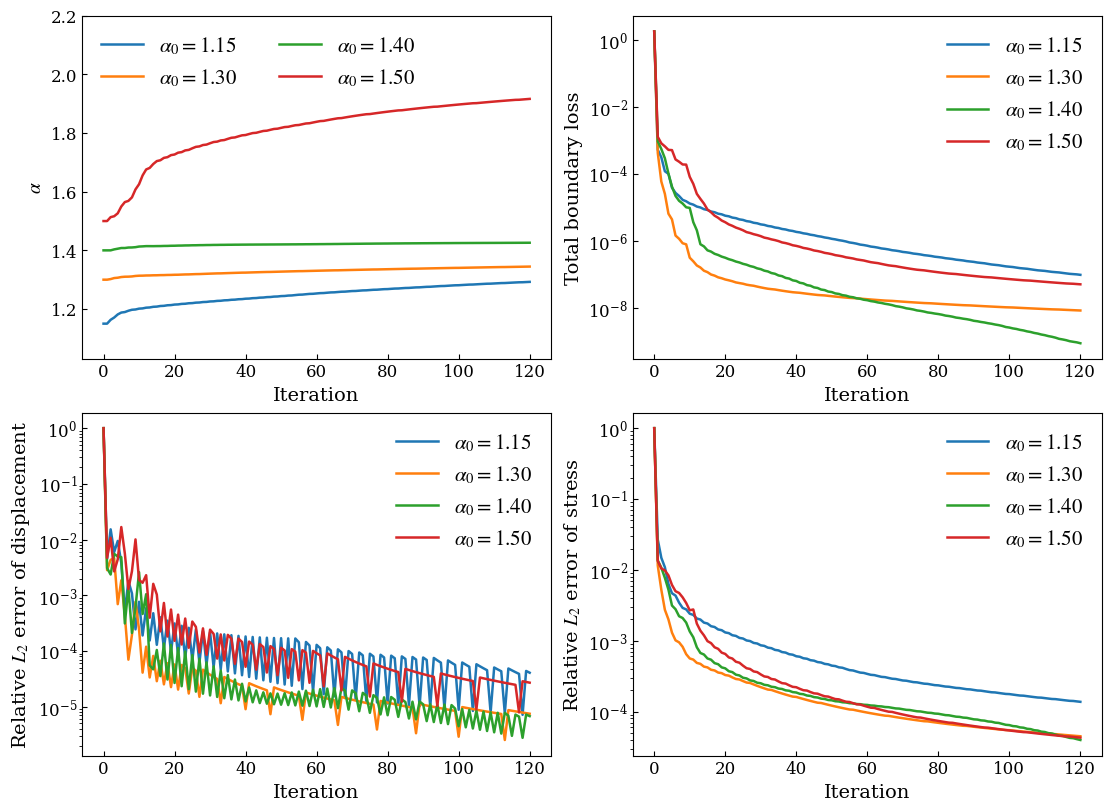

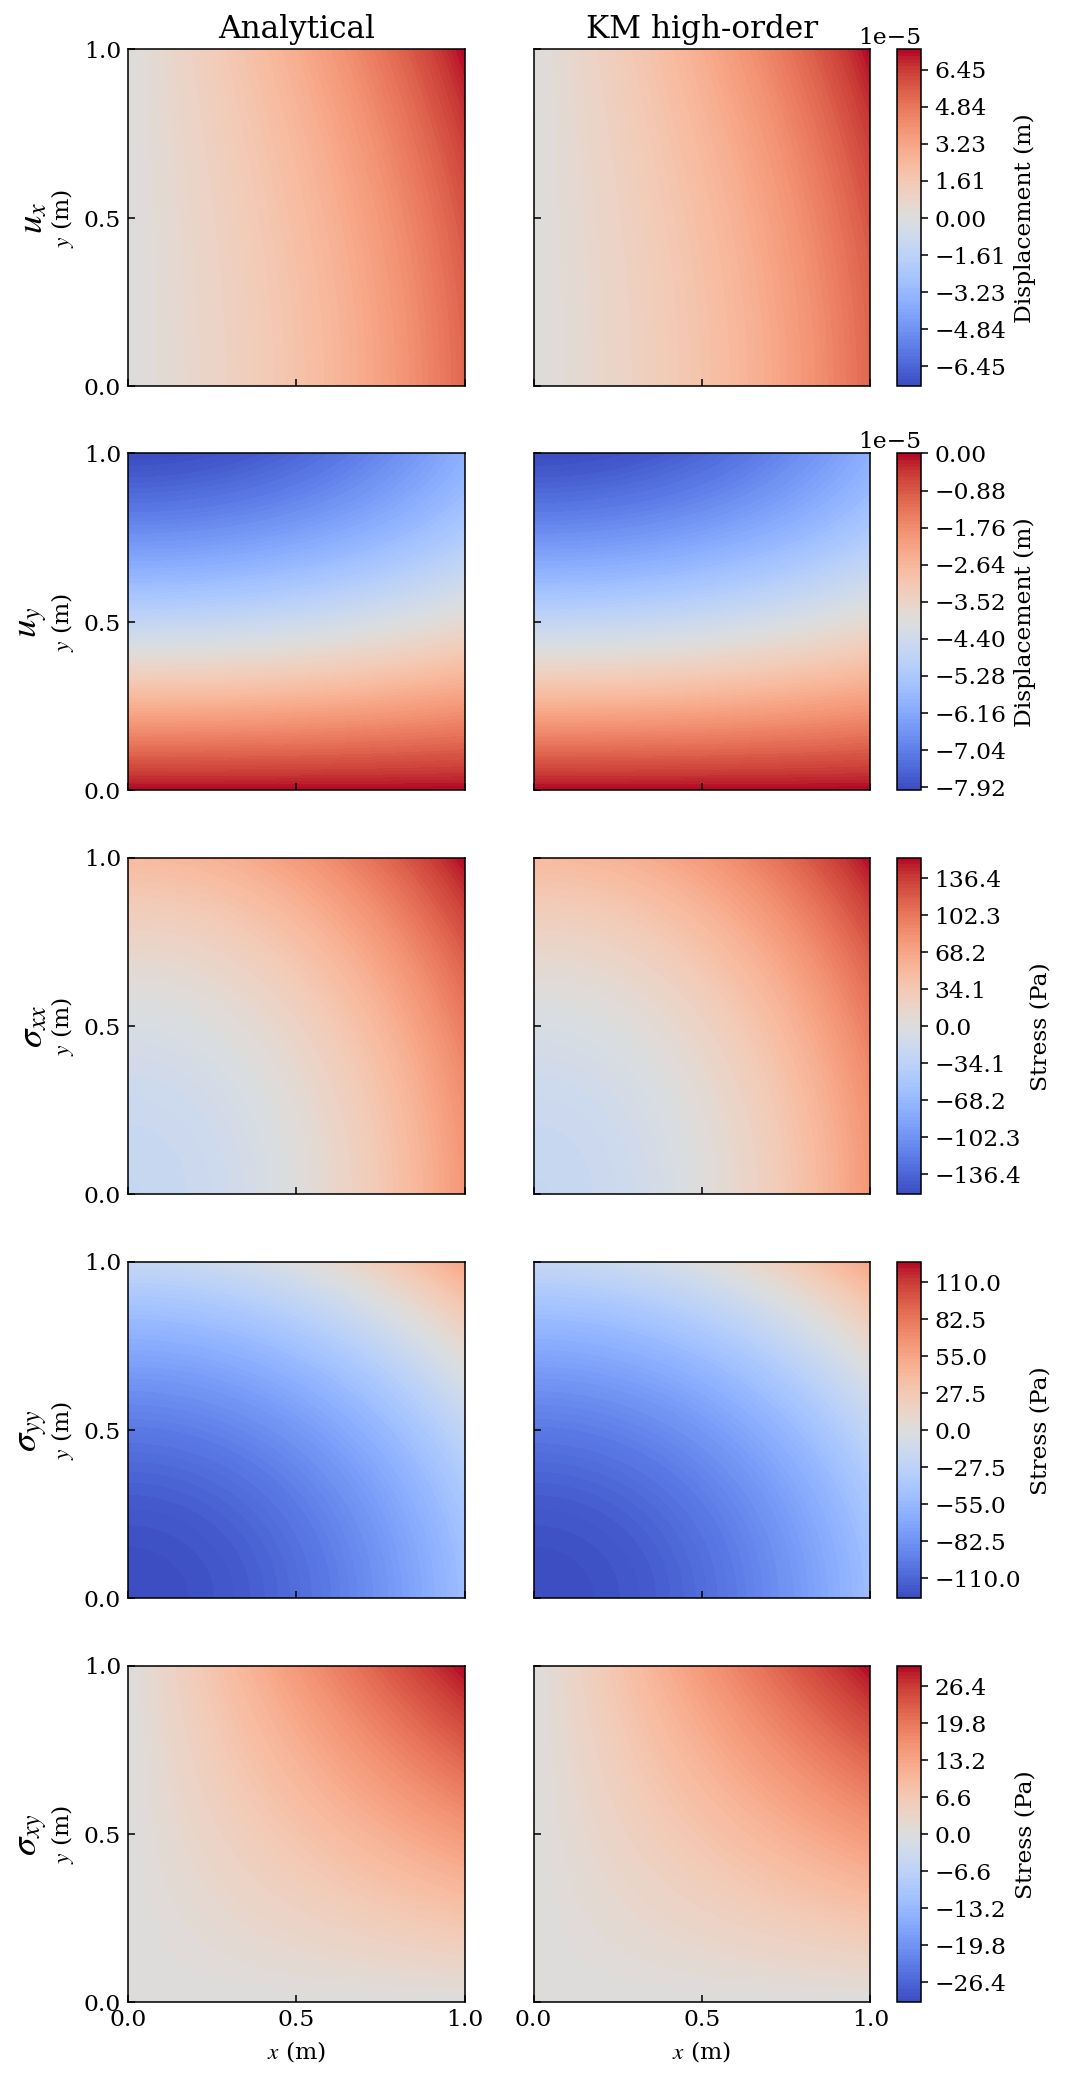

In [4]:
best_run, error_rows = main()
